# Closed-Loop Vehicle Control

This notebook integrates longitudinal speed control and lateral steering control
within a simplified kinematic bicycle model.

The closed-loop system uses vehicle-state feedback to continuously update
acceleration and steering commands.

The implementation covers:

- Reference trajectory generation
- Vehicle state representation
- Longitudinal PID speed control
- Lateral trajectory tracking control
- Kinematic bicycle-model simulation
- Tracking-error and control-performance evaluation
- Simulation validation

In [16]:
# 1-19D — Environment and Library Setup

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

print("Libraries imported successfully.")

Libraries imported successfully.


## Closed-Loop Control Architecture

The controller receives the vehicle's current state and compares it with the
desired reference trajectory and target speed.

The control loop consists of:

1. Measuring the current vehicle state
2. Calculating longitudinal speed error
3. Calculating lateral and heading errors
4. Generating acceleration and steering commands
5. Updating the vehicle state using the vehicle model
6. Repeating the process throughout the simulation

In [17]:
# 2-19D — Simulation Parameters and Reference Trajectory

simulation_time = 20.0
dt = 0.05

time = np.arange(0.0, simulation_time + dt, dt)

target_speed = 5.0
wheelbase = 2.5

max_acceleration = 3.0
min_acceleration = -4.0

max_steering_angle = np.deg2rad(30.0)

# Reference trajectory
reference_x = np.linspace(0.0, 100.0, 2001)
reference_y = 2.0 * np.sin(0.08 * reference_x)

reference_heading = np.arctan2(
    np.gradient(reference_y),
    np.gradient(reference_x)
)

print(f"Simulation duration: {simulation_time:.1f} seconds")
print(f"Time step: {dt:.2f} seconds")
print(f"Target speed: {target_speed:.1f} m/s")
print(f"Wheelbase: {wheelbase:.2f} m")

Simulation duration: 20.0 seconds
Time step: 0.05 seconds
Target speed: 5.0 m/s
Wheelbase: 2.50 m


## Vehicle State and Parameters

The vehicle is represented using the following state variables:

- x-position
- y-position
- Heading angle
- Vehicle speed

The kinematic bicycle model assumes low-speed vehicle motion and neglects
tire slip and detailed vehicle dynamics.

In [18]:
# 3-19D — Vehicle State Initialization

initial_x = 0.0
initial_y = -1.0
initial_heading = 0.0
initial_speed = 0.0

vehicle_state = np.array([
    initial_x,
    initial_y,
    initial_heading,
    initial_speed
], dtype=float)

print("Initial vehicle state:")
print(f"x-position: {vehicle_state[0]:.2f} m")
print(f"y-position: {vehicle_state[1]:.2f} m")
print(f"Heading: {np.rad2deg(vehicle_state[2]):.2f} degrees")
print(f"Speed: {vehicle_state[3]:.2f} m/s")

Initial vehicle state:
x-position: 0.00 m
y-position: -1.00 m
Heading: 0.00 degrees
Speed: 0.00 m/s


## Longitudinal PID Controller

The longitudinal controller regulates vehicle speed.

The control error is defined as:

\[
e_v(t) = v_{\text{target}} - v(t)
\]

The PID control law is:

\[
u(t) = K_p e(t) + K_i \int e(t)dt + K_d \frac{de(t)}{dt}
\]

The resulting control command is interpreted as longitudinal acceleration.
Acceleration is limited to the defined physical operating range.

In [19]:
# 4-19D — Longitudinal PID Controller

class PIDController:

    def __init__(
        self,
        kp,
        ki,
        kd,
        dt,
        output_min,
        output_max
    ):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.dt = dt

        self.output_min = output_min
        self.output_max = output_max

        self.integral = 0.0
        self.previous_error = 0.0

    def reset(self):
        self.integral = 0.0
        self.previous_error = 0.0

    def compute(self, error):

        self.integral += error * self.dt

        derivative = (
            error - self.previous_error
        ) / self.dt

        output = (
            self.kp * error
            + self.ki * self.integral
            + self.kd * derivative
        )

        output = np.clip(
            output,
            self.output_min,
            self.output_max
        )

        self.previous_error = error

        return output


speed_controller = PIDController(
    kp=0.8,
    ki=0.15,
    kd=0.05,
    dt=dt,
    output_min=min_acceleration,
    output_max=max_acceleration
)

print("Longitudinal PID controller initialized.")

Longitudinal PID controller initialized.


## Lateral Steering Controller

The lateral controller uses the nearest reference point and heading error
to calculate a steering command.

The control law combines:

- Cross-track error
- Heading error

The steering command is limited to the maximum steering angle.

This is a simplified feedback controller intended for demonstrating
closed-loop trajectory tracking.

In [20]:
# 5-19D — Lateral Steering Controller

def normalize_angle(angle):

    return (angle + np.pi) % (2.0 * np.pi) - np.pi


def calculate_nearest_point(
    x,
    y,
    reference_x,
    reference_y
):

    distances = np.hypot(
        reference_x - x,
        reference_y - y
    )

    nearest_index = np.argmin(distances)

    return nearest_index, distances[nearest_index]


def calculate_steering_command(
    state,
    reference_x,
    reference_y,
    reference_heading,
    wheelbase,
    lateral_gain,
    heading_gain,
    maximum_steering
):

    x, y, heading, speed = state

    nearest_index, cross_track_distance = calculate_nearest_point(
        x,
        y,
        reference_x,
        reference_y
    )

    target_x = reference_x[nearest_index]
    target_y = reference_y[nearest_index]
    target_heading = reference_heading[nearest_index]

    dx = target_x - x
    dy = target_y - y

    cross_track_error = (
        -np.sin(target_heading) * dx
        + np.cos(target_heading) * dy
    )

    heading_error = normalize_angle(
        target_heading - heading
    )

    steering_command = (
        lateral_gain * cross_track_error
        + heading_gain * heading_error
    )

    steering_command = np.clip(
        steering_command,
        -maximum_steering,
        maximum_steering
    )

    return (
        steering_command,
        cross_track_error,
        heading_error,
        cross_track_distance,
        nearest_index
    )


print("Lateral steering controller initialized.")

Lateral steering controller initialized.


## Kinematic Bicycle Model

The vehicle state is propagated using the kinematic bicycle model:

\[
\dot{x} = v\cos(\theta)
\]

\[
\dot{y} = v\sin(\theta)
\]

\[
\dot{\theta} = \frac{v}{L}\tan(\delta)
\]

\[
\dot{v} = a
\]

where:

- \(v\) is vehicle speed
- \(L\) is wheelbase
- \(\delta\) is steering angle
- \(a\) is longitudinal acceleration

In [21]:
# 6-19D — Kinematic Bicycle Model

def update_vehicle_state(
    state,
    acceleration,
    steering_angle,
    wheelbase,
    dt
):

    x, y, heading, speed = state

    new_x = x + speed * np.cos(heading) * dt
    new_y = y + speed * np.sin(heading) * dt

    new_heading = (
        heading
        + (speed / wheelbase)
        * np.tan(steering_angle)
        * dt
    )

    new_speed = max(
        0.0,
        speed + acceleration * dt
    )

    new_heading = normalize_angle(new_heading)

    return np.array([
        new_x,
        new_y,
        new_heading,
        new_speed
    ])


print("Vehicle model function defined.")

Vehicle model function defined.


## Closed-Loop Simulation

At every simulation step:

1. The current speed is compared with the target speed.
2. The PID controller calculates acceleration.
3. The lateral controller calculates steering.
4. The vehicle model updates the state.
5. Position, speed, acceleration, steering, and tracking errors are recorded.

Both controllers operate using feedback from the simulated vehicle state.

In [22]:
# 7-19D — Closed-Loop Vehicle Simulation

lateral_gain = 0.8
heading_gain = 1.5

speed_controller.reset()

state = vehicle_state.copy()

state_history = []
acceleration_history = []
steering_history = []
speed_error_history = []
cross_track_error_history = []
heading_error_history = []
nearest_distance_history = []

for current_time in time:

    x, y, heading, speed = state

    speed_error = target_speed - speed

    acceleration_command = speed_controller.compute(
        speed_error
    )

    (
        steering_command,
        cross_track_error,
        heading_error,
        nearest_distance,
        nearest_index
    ) = calculate_steering_command(
        state,
        reference_x,
        reference_y,
        reference_heading,
        wheelbase,
        lateral_gain,
        heading_gain,
        max_steering_angle
    )

    state_history.append(state.copy())
    acceleration_history.append(acceleration_command)
    steering_history.append(steering_command)
    speed_error_history.append(speed_error)
    cross_track_error_history.append(cross_track_error)
    heading_error_history.append(heading_error)
    nearest_distance_history.append(nearest_distance)

    state = update_vehicle_state(
        state,
        acceleration_command,
        steering_command,
        wheelbase,
        dt
    )

state_history = np.array(state_history)
acceleration_history = np.array(acceleration_history)
steering_history = np.array(steering_history)
speed_error_history = np.array(speed_error_history)
cross_track_error_history = np.array(cross_track_error_history)
heading_error_history = np.array(heading_error_history)
nearest_distance_history = np.array(nearest_distance_history)

print("Closed-loop simulation completed.")
print(f"Recorded simulation states: {len(state_history)}")

Closed-loop simulation completed.
Recorded simulation states: 401


## Vehicle Trajectory Evaluation

The simulated vehicle trajectory is compared with the reference trajectory.

The plot provides a visual assessment of the vehicle's ability to follow
the desired path while applying feedback-based steering control.

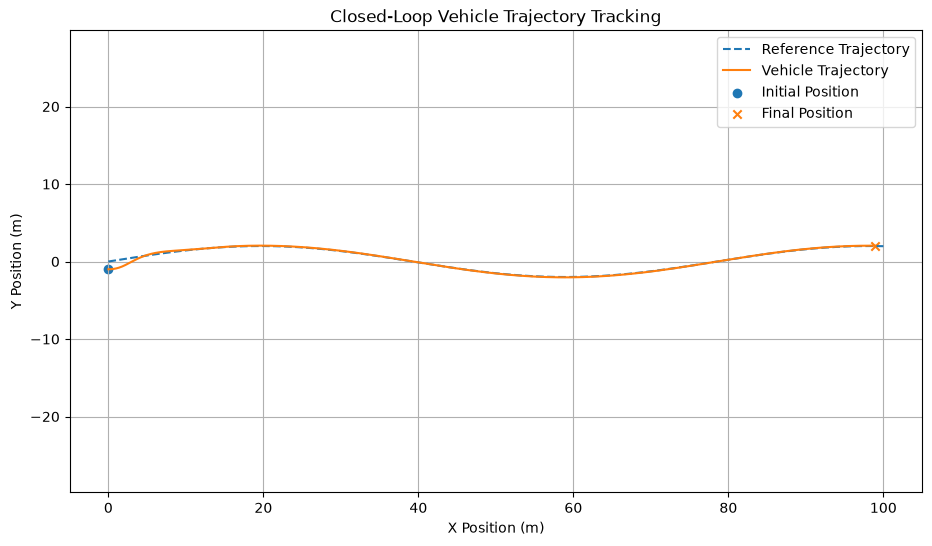

In [23]:
# 8-19D — Vehicle Trajectory Visualization

plt.figure(figsize=(11, 6))

plt.plot(
    reference_x,
    reference_y,
    linestyle="--",
    label="Reference Trajectory"
)

plt.plot(
    state_history[:, 0],
    state_history[:, 1],
    label="Vehicle Trajectory"
)

plt.scatter(
    state_history[0, 0],
    state_history[0, 1],
    marker="o",
    label="Initial Position"
)

plt.scatter(
    state_history[-1, 0],
    state_history[-1, 1],
    marker="x",
    label="Final Position"
)

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")
plt.title("Closed-Loop Vehicle Trajectory Tracking")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

## Vehicle Speed Response

The speed response is evaluated against the target speed.

The PID controller adjusts acceleration based on the instantaneous speed error,
accumulated error, and rate of error change.

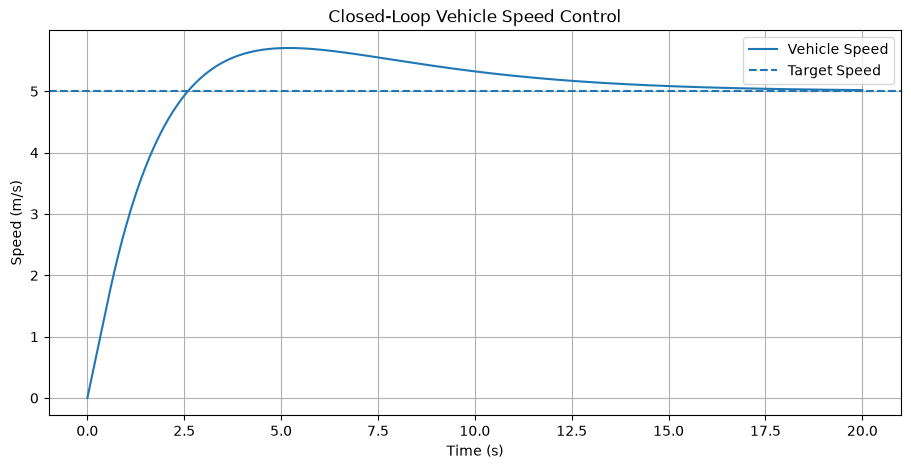

In [24]:
# 9-19D — Vehicle Speed Response

plt.figure(figsize=(11, 5))

plt.plot(
    time,
    state_history[:, 3],
    label="Vehicle Speed"
)

plt.axhline(
    target_speed,
    linestyle="--",
    label="Target Speed"
)

plt.xlabel("Time (s)")
plt.ylabel("Speed (m/s)")
plt.title("Closed-Loop Vehicle Speed Control")
plt.legend()
plt.grid(True)
plt.show()

## Steering and Acceleration Commands

The control commands are visualized to understand the behaviour of the
longitudinal and lateral controllers.

Acceleration is expressed in m/s², while steering is converted to degrees
for easier interpretation.

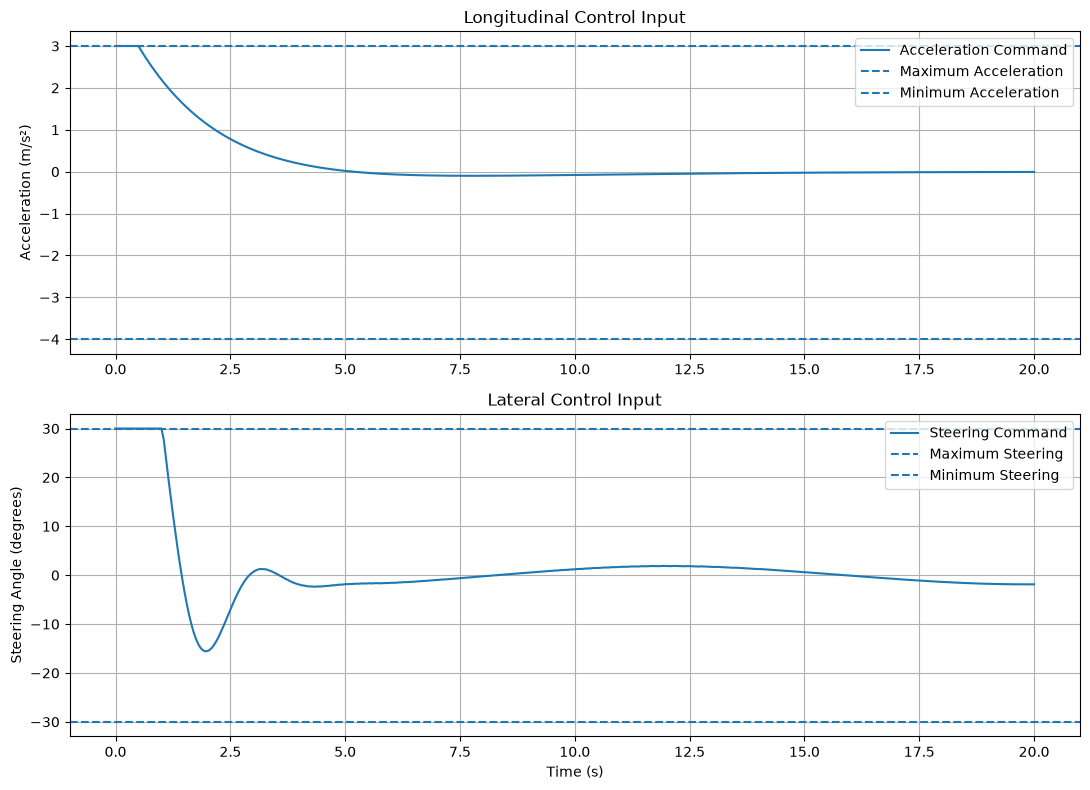

In [25]:
# 10-19D — Control Input Visualization

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].plot(
    time,
    acceleration_history,
    label="Acceleration Command"
)

axes[0].axhline(
    max_acceleration,
    linestyle="--",
    label="Maximum Acceleration"
)

axes[0].axhline(
    min_acceleration,
    linestyle="--",
    label="Minimum Acceleration"
)

axes[0].set_ylabel("Acceleration (m/s²)")
axes[0].set_title("Longitudinal Control Input")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    time,
    np.rad2deg(steering_history),
    label="Steering Command"
)

axes[1].axhline(
    np.rad2deg(max_steering_angle),
    linestyle="--",
    label="Maximum Steering"
)

axes[1].axhline(
    -np.rad2deg(max_steering_angle),
    linestyle="--",
    label="Minimum Steering"
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Steering Angle (degrees)")
axes[1].set_title("Lateral Control Input")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Tracking Error Evaluation

The following metrics are calculated:

- Mean absolute cross-track error
- Maximum absolute cross-track error
- Final absolute cross-track error
- Mean absolute speed error
- Final absolute speed error
- Maximum steering angle
- Maximum acceleration
- Minimum acceleration

These metrics provide a quantitative assessment of closed-loop control
performance.

In [26]:
# 11-19D — Closed-Loop Performance Metrics

absolute_cross_track_error = np.abs(
    cross_track_error_history
)

absolute_speed_error = np.abs(
    speed_error_history
)

mean_cross_track_error = np.mean(
    absolute_cross_track_error
)

maximum_cross_track_error = np.max(
    absolute_cross_track_error
)

final_cross_track_error = absolute_cross_track_error[-1]

mean_speed_error = np.mean(
    absolute_speed_error
)

final_speed_error = absolute_speed_error[-1]

maximum_steering_angle = np.max(
    np.abs(np.rad2deg(steering_history))
)

maximum_acceleration_value = np.max(
    acceleration_history
)

minimum_acceleration_value = np.min(
    acceleration_history
)

print("Closed-Loop Vehicle Control Metrics")
print("------------------------------------")
print(
    f"Mean absolute cross-track error: "
    f"{mean_cross_track_error:.4f} m"
)

print(
    f"Maximum absolute cross-track error: "
    f"{maximum_cross_track_error:.4f} m"
)

print(
    f"Final absolute cross-track error: "
    f"{final_cross_track_error:.4f} m"
)

print(
    f"Mean absolute speed error: "
    f"{mean_speed_error:.4f} m/s"
)

print(
    f"Final absolute speed error: "
    f"{final_speed_error:.4f} m/s"
)

print(
    f"Maximum steering angle: "
    f"{maximum_steering_angle:.4f} degrees"
)

print(
    f"Maximum acceleration: "
    f"{maximum_acceleration_value:.4f} m/s²"
)

print(
    f"Minimum acceleration: "
    f"{minimum_acceleration_value:.4f} m/s²"
)

Closed-Loop Vehicle Control Metrics
------------------------------------
Mean absolute cross-track error: 0.1090 m
Maximum absolute cross-track error: 1.0472 m
Final absolute cross-track error: 0.0434 m
Mean absolute speed error: 0.5046 m/s
Final absolute speed error: 0.0192 m/s
Maximum steering angle: 30.0000 degrees
Maximum acceleration: 3.0000 m/s²
Minimum acceleration: -0.0979 m/s²


## Tracking Error Visualization

The cross-track error and heading error are plotted over time.

A decreasing tracking error indicates that the feedback controller is
correcting the vehicle's deviation from the reference trajectory.

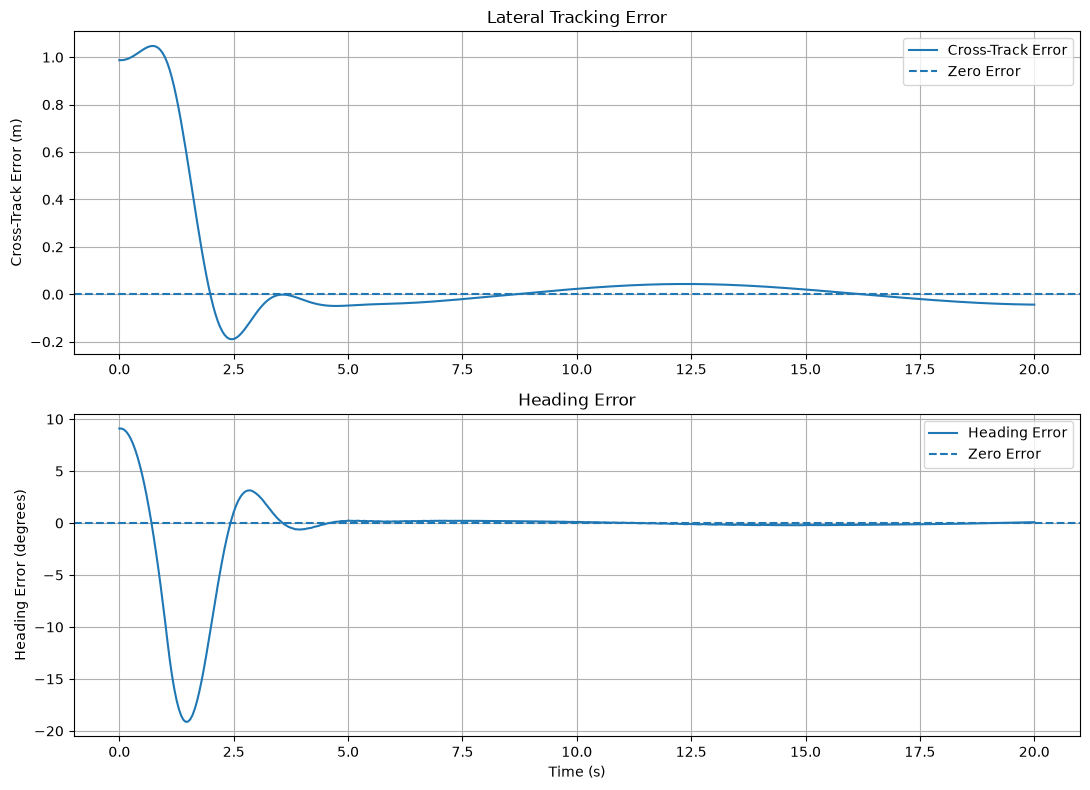

In [27]:
# 12-19D — Tracking Error Visualization

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].plot(
    time,
    cross_track_error_history,
    label="Cross-Track Error"
)

axes[0].axhline(
    0.0,
    linestyle="--",
    label="Zero Error"
)

axes[0].set_ylabel("Cross-Track Error (m)")
axes[0].set_title("Lateral Tracking Error")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(
    time,
    np.rad2deg(heading_error_history),
    label="Heading Error"
)

axes[1].axhline(
    0.0,
    linestyle="--",
    label="Zero Error"
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Heading Error (degrees)")
axes[1].set_title("Heading Error")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Closed-Loop Control Summary

The integrated controller combines longitudinal and lateral feedback.

The longitudinal PID controller regulates vehicle speed, while the lateral
controller adjusts steering based on cross-track and heading errors.

The evaluation metrics are used to assess:

- Speed regulation
- Trajectory tracking
- Steering behaviour
- Control-command limitations
- Overall closed-loop response

The simplified model does not represent tire forces, vehicle slip,
actuator delays, or detailed vehicle dynamics.

In [28]:
# 13-19D — Closed-Loop Control Summary

final_x = state_history[-1, 0]
final_y = state_history[-1, 1]
final_speed = state_history[-1, 3]

print("Closed-Loop Control Summary")
print("---------------------------")
print(f"Final vehicle X position: {final_x:.4f} m")
print(f"Final vehicle Y position: {final_y:.4f} m")
print(f"Final vehicle speed: {final_speed:.4f} m/s")
print(f"Target speed: {target_speed:.4f} m/s")
print(
    f"Final speed error: "
    f"{target_speed - final_speed:.4f} m/s"
)
print(
    f"Final cross-track error: "
    f"{final_cross_track_error:.4f} m"
)

Closed-Loop Control Summary
---------------------------
Final vehicle X position: 98.9628 m
Final vehicle Y position: 2.0395 m
Final vehicle speed: 5.0192 m/s
Target speed: 5.0000 m/s
Final speed error: -0.0192 m/s
Final cross-track error: 0.0434 m


## Validation

The validation checks confirm that the simulation generated valid numerical
outputs and that the primary state and control arrays have consistent lengths.

The validation does not establish real-vehicle performance.

In [29]:
# 14-19D — Closed-Loop Simulation Validation

assert len(time) == len(state_history)
assert len(time) == len(acceleration_history)
assert len(time) == len(steering_history)

assert state_history.shape[1] == 4

assert np.all(np.isfinite(state_history))
assert np.all(np.isfinite(acceleration_history))
assert np.all(np.isfinite(steering_history))
assert np.all(np.isfinite(cross_track_error_history))
assert np.all(np.isfinite(speed_error_history))

assert np.all(
    np.abs(steering_history) <= max_steering_angle + 1e-9
)

assert np.all(
    acceleration_history <= max_acceleration + 1e-9
)

assert np.all(
    acceleration_history >= min_acceleration - 1e-9
)

print("Closed-loop vehicle control validation completed successfully.")
print("All state, control, and error arrays contain valid values.")

Closed-loop vehicle control validation completed successfully.
All state, control, and error arrays contain valid values.
